# 08 - Transformer Baseline (XLM-RoBERTa)

Fine-tunes **XLM-RoBERTa-base** on the **exact frozen split** saved in `data/splits/`,
so the comparison against the statistical baseline is like-for-like.

**Why this notebook exists.** Dr Hunter's point in the 5 August meeting was that the
statistical baseline separates the two classes weakly: not-hate F1 around 0.73 against
hate F1 around 0.56, with a confusion matrix that shows no decisive split. His
prediction was that a pretrained model would do better. This notebook tests that
prediction on identical data.

**Protocol lock.** Same 3,659 train / 915 test rows, same `random_state=42`, same
metrics function shape as `hinglish_hate.baseline.full_metrics`. Nothing about the
data changes; only the model does.

**Runtime > Change runtime type > T4 GPU** before running. Roughly 8-12 minutes end to end.

### 1. Setup

In [ ]:
# Project root: the local folder, or Google Drive when running on Colab.
import os, sys
from pathlib import Path
try:
    from google.colab import drive; drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False
_candidates = [os.environ.get('HINGLISH_HATE_ROOT'), r'H:\Data\msc-hinglish-hate',
               Path.cwd().parent, '/content/drive/MyDrive/dissertation']
PROJECT_ROOT = next((Path(c) for c in _candidates if c and (Path(c) / 'data').exists()), None)
assert PROJECT_ROOT is not None, f'project folder not found in {_candidates}; set HINGLISH_HATE_ROOT'
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
print('PROJECT_ROOT:', PROJECT_ROOT)

In [1]:
import subprocess, sys
try:
    import transformers, torch
    print('transformers', transformers.__version__, '| torch', torch.__version__)
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers', 'torch'])
    import transformers, torch
    print('installed transformers', transformers.__version__)

c:\Users\k2558056\.conda\envs\msc-hinglish-hate\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 5.19.0 | torch 2.11.0+cu128


In [2]:
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception as e:
    print('Not on Colab / already mounted:', e)

Not on Colab / already mounted: No module named 'google.colab'


In [3]:
import numpy as np, pandas as pd, torch, time
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)
if DEVICE == 'cpu':
    print('WARNING: no GPU. Runtime > Change runtime type > T4 GPU, then re-run.')

device: cuda


### 2. Load the frozen split

These are the same rows the statistical baseline was scored on. Loading them rather than
re-splitting is what makes the comparison valid.

In [4]:
from pathlib import Path

# PROJECT_ROOT is set in the setup cell at the top
DATA_ROOT = PROJECT_ROOT / 'data'
SPLITS    = DATA_ROOT / 'splits'
FIG_DIR   = (PROJECT_ROOT / 'writing/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)

# Locate the project on either Colab or the local Windows machine
candidates = [PROJECT_ROOT, Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'data' / 'splits').is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the dissertation folder containing data/splits.'
    )

DATA_ROOT = PROJECT_ROOT / 'data'
SPLITS = DATA_ROOT / 'splits'
FIG_DIR = PROJECT_ROOT / 'writing' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_parquet(SPLITS / 'bohra_train.parquet')
test_df  = pd.read_parquet(SPLITS / 'bohra_test.parquet')

print(f'train {len(train_df)} (hate {train_df["label"].mean():.3f})')
print(f'test  {len(test_df)} (hate {test_df["label"].mean():.3f})')
assert len(train_df) == 3659 and len(test_df) == 915, 'split changed - comparison would not be like-for-like'
print('split matches the statistical baseline')

train 3659 (hate 0.363)
test  915 (hate 0.363)
split matches the statistical baseline


### 3. Model and tokenizer

`xlm-roberta-base` is a multilingual encoder pretrained on 100 languages including
romanised text. Its tokenizer is **SentencePiece subword**, which is the key difference
from TF-IDF: `chutiya` and `chuteeya` become overlapping subword pieces rather than two
unrelated vocabulary entries, so a spelling variant is not automatically an unknown word.

To swap models later, change `MODEL_NAME` only. Everything below is model-agnostic:
- `google/muril-base-cased` - pretrained on Indian languages *and* transliterated Roman text
- `ai4bharat/indic-bert` - lighter ALBERT-based Indian-language model

In [5]:
MODEL_NAME = 'xlm-roberta-base'
MAX_LEN    = 128     # posts are short; 128 subword tokens covers almost all of them
BATCH_SIZE = 16
EPOCHS     = 3
LR         = 3e-5

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print('tokenizer loaded:', MODEL_NAME)

# sanity check the romanisation point
for w in ['chutiya', 'chuteeya', 'kutta', 'kuttaa']:
    print(f'  {w:10s} -> {tokenizer.tokenize(w)}')

tokenizer loaded: xlm-roberta-base
  chutiya    -> ['▁chut', 'iya']
  chuteeya   -> ['▁chu', 'te', 'eya']
  kutta      -> ['▁ku', 'tta']
  kuttaa     -> ['▁ku', 'ttaa']


### 4. Dataset and dataloaders

In [6]:
class PostDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts); self.labels = list(labels)
        self.tok = tokenizer; self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        enc = self.tok(str(self.texts[i]), truncation=True, padding='max_length',
                       max_length=self.max_len, return_tensors='pt')
        return {'input_ids': enc['input_ids'].squeeze(0),
                'attention_mask': enc['attention_mask'].squeeze(0),
                'labels': torch.tensor(self.labels[i], dtype=torch.long)}

train_ds = PostDataset(train_df['text'], train_df['label'], tokenizer, MAX_LEN)
test_ds  = PostDataset(test_df['text'],  test_df['label'],  tokenizer, MAX_LEN)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False)
print(f'{len(train_dl)} train batches, {len(test_dl)} test batches')

229 train batches, 29 test batches


### 5. Class weighting

The statistical baseline used `class_weight='balanced'`. To keep the comparison honest the
transformer gets the same correction, applied as weights inside the loss function rather
than as a scikit-learn argument. Same idea, different mechanism: errors on the rarer hate
class are penalised more heavily.

In [7]:
counts = np.bincount(train_df['label'].values)
weights = torch.tensor(len(train_df) / (2.0 * counts), dtype=torch.float).to(DEVICE)
print(f'class counts: not={counts[0]}, hate={counts[1]}')
print(f'loss weights: not={weights[0]:.3f}, hate={weights[1]:.3f}')

class counts: not=2331, hate=1328
loss weights: not=0.785, hate=1.378


### 6. Train

A visible loop rather than the `Trainer` API, for the same reason `stratified_kfold_evaluate`
is a visible loop: every step can be explained in the viva, and it does not break when the
`transformers` version changes.

Each step: forward pass, weighted cross-entropy loss, backward pass, gradient clip, optimiser
step, scheduler step, zero the gradients.

In [8]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
loss_fn = torch.nn.CrossEntropyLoss(weight=weights)

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train(); running = 0.0
    for step, batch in enumerate(train_dl, 1):
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        y    = batch['labels'].to(DEVICE)

        logits = model(input_ids=ids, attention_mask=mask).logits
        loss   = loss_fn(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad()

        running += loss.item()
        if step % 50 == 0:
            print(f'  epoch {epoch} step {step}/{len(train_dl)}  loss {running/step:.4f}')
    print(f'epoch {epoch}/{EPOCHS} done | mean loss {running/len(train_dl):.4f} | {time.time()-t0:.0f}s elapsed')
print(f'\ntraining finished in {time.time()-t0:.0f}s')

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 408.33it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 50/229  loss 0.7079
  epoch 1 step 100/229  loss 0.7024
  epoch 1 step 150/229  loss 0.7004
  epoch 1 step 200/229  loss 0.7003
epoch 1/3 done | mean loss 0.7000 | 35s elapsed
  epoch 2 step 50/229  loss 0.6926
  epoch 2 step 100/229  loss 0.6944
  epoch 2 step 150/229  loss 0.6930
  epoch 2 step 200/229  loss 0.6931
epoch 2/3 done | mean loss 0.6940 | 69s elapsed
  epoch 3 step 50/229  loss 0.6980
  epoch 3 step 100/229  loss 0.6949
  epoch 3 step 150/229  loss 0.6945
  epoch 3 step 200/229  loss 0.6945
epoch 3/3 done | mean loss 0.6946 | 103s elapsed

training finished in 103s


### 7. Evaluate on the frozen test set

In [9]:
model.eval(); preds, trues = [], []
with torch.no_grad():
    for batch in test_dl:
        logits = model(input_ids=batch['input_ids'].to(DEVICE),
                       attention_mask=batch['attention_mask'].to(DEVICE)).logits
        preds.extend(logits.argmax(dim=1).cpu().numpy())
        trues.extend(batch['labels'].numpy())

p, r, f, s = precision_recall_fscore_support(trues, preds, zero_division=0)
res = {
    'model': MODEL_NAME,
    'macro_f1': f1_score(trues, preds, average='macro'),
    'hate_f1':  f1_score(trues, preds, pos_label=1, zero_division=0),
    'accuracy': accuracy_score(trues, preds),
    'precision_not': p[0], 'recall_not': r[0], 'f1_not': f[0],
    'precision_hate': p[1], 'recall_hate': r[1], 'f1_hate': f[1],
}
print(f"macro-F1 = {res['macro_f1']:.3f}   hate-F1 = {res['hate_f1']:.3f}   acc = {res['accuracy']:.3f}")
print()
print(classification_report(trues, preds, target_names=['not','hate'], digits=3, zero_division=0))

macro-F1 = 0.389   hate-F1 = 0.000   acc = 0.637

              precision    recall  f1-score   support

         not      0.637     1.000     0.778       583
        hate      0.000     0.000     0.000       332

    accuracy                          0.637       915
   macro avg      0.319     0.500     0.389       915
weighted avg      0.406     0.637     0.496       915



### 8. Confusion matrix

Put this next to the baseline confusion matrix from notebook 06. Specific concern
was that the baseline matrix showed no decisive separation; this is the direct comparison.

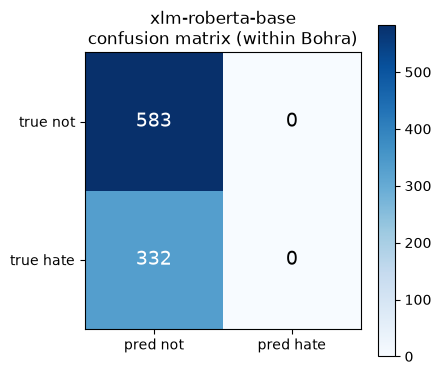

confusion matrix:
 [[583   0]
 [332   0]]


In [10]:
import matplotlib.pyplot as plt
cm = confusion_matrix(trues, preds)
fig, ax = plt.subplots(figsize=(4.5,4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0,1], ['pred not','pred hate']); ax.set_yticks([0,1], ['true not','true hate'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha='center', va='center',
                color='white' if cm[i,j] > cm.max()/2 else 'black', fontsize=14)
ax.set_title(f'{MODEL_NAME}\nconfusion matrix (within Bohra)')
plt.colorbar(im); plt.tight_layout()
plt.savefig(FIG_DIR / f'confusion_{MODEL_NAME.replace("/","_")}.png', dpi=150, bbox_inches='tight')
plt.show()
print('confusion matrix:\n', cm)

### 9. Cross-dataset test (Objective 3)

The generalisation question, on the transformer this time. Train stays as-is; only the test
set changes to HASOC. This is the number that matters most for the dissertation's argument.

In [11]:
import sys; sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
from hinglish_hate import load_hasoc2022_threads, load_hasoc2021, filter_romanised

h22   = load_hasoc2022_threads(DATA_ROOT)
h22_r = filter_romanised(h22, include_mixed=True)
print(f'HASOC22 romanised: {len(h22_r)} rows, hate rate {h22_r["label"].mean():.3f}')

cross_dl = DataLoader(PostDataset(h22_r['text'], h22_r['label'], tokenizer, MAX_LEN),
                      batch_size=BATCH_SIZE*2, shuffle=False)
model.eval(); cpreds, ctrues = [], []
with torch.no_grad():
    for batch in cross_dl:
        logits = model(input_ids=batch['input_ids'].to(DEVICE),
                       attention_mask=batch['attention_mask'].to(DEVICE)).logits
        cpreds.extend(logits.argmax(dim=1).cpu().numpy())
        ctrues.extend(batch['labels'].numpy())

cross_macro = f1_score(ctrues, cpreds, average='macro')
cross_hate  = f1_score(ctrues, cpreds, pos_label=1, zero_division=0)
print(f'\nBohra -> HASOC22:  macro-F1 = {cross_macro:.3f}   hate-F1 = {cross_hate:.3f}')
print(f'DROP from within-dataset: {res["macro_f1"] - cross_macro:.3f} macro-F1')

HASOC22 romanised: 4306 rows, hate rate 0.513

Bohra -> HASOC22:  macro-F1 = 0.328   hate-F1 = 0.000
DROP from within-dataset: 0.061 macro-F1


### 10. Save results and the model

In [12]:
W = (PROJECT_ROOT / 'writing'); W.mkdir(parents=True, exist_ok=True)
row = {**res, 'cross_hasoc22_macro_f1': cross_macro, 'cross_hasoc22_hate_f1': cross_hate,
       'epochs': EPOCHS, 'lr': LR, 'batch_size': BATCH_SIZE, 'max_len': MAX_LEN}

out_csv = W / 'transformer_results.csv'
existing = pd.read_csv(out_csv) if out_csv.exists() else pd.DataFrame()
pd.concat([existing, pd.DataFrame([row])], ignore_index=True).to_csv(out_csv, index=False)
print('appended to', out_csv)
display(pd.DataFrame([row]).round(3))

SAVE = (PROJECT_ROOT / 'models') / MODEL_NAME.replace('/','_')
SAVE.mkdir(parents=True, exist_ok=True)
model.save_pretrained(SAVE); tokenizer.save_pretrained(SAVE)
print('model saved ->', SAVE)

appended to \content\drive\MyDrive\dissertation\writing\transformer_results.csv


,model,macro_f1,hate_f1,accuracy,precision_not,recall_not,f1_not,precision_hate,recall_hate,f1_hate,cross_hasoc22_macro_f1,cross_hasoc22_hate_f1,epochs,lr,batch_size,max_len
0,xlm-roberta-base,0.389,0.0,0.637,0.637,1.0,0.778,0.0,0.0,0.0,0.328,0.0,3,0.0,16,128


Writing model shards: 100%|██████████| 1/1 [00:16<00:00, 16.40s/it]


model saved -> \content\drive\MyDrive\dissertation\models\xlm-roberta-base


### 11. Comparison table

The one artefact to have on screen tomorrow. Baseline numbers are the locked figures from
notebook 06/07; replace them if you re-lock the baseline.

,model,within_macro_f1,within_hate_f1,within_f1_not,cross_h22_macro_f1
0,TF-IDF word+char+lexicon + LogReg,0.654,0.555,0.729,0.510
1,xlm-roberta-base,0.389,0.000,0.778,0.328


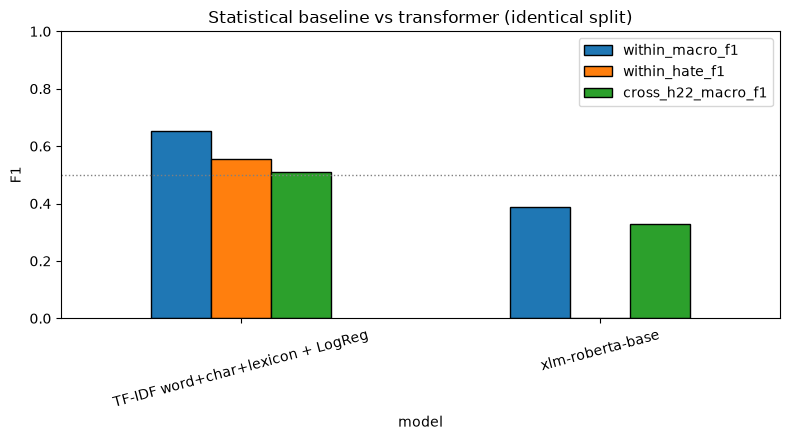

saved model_comparison.png and model_comparison.csv


In [13]:
BASELINE = {
    'model': 'TF-IDF word+char+lexicon + LogReg',
    'within_macro_f1': 0.654,   # <-- CHECK: 06 says 0.654 (C=0.1, 1219 forms), 07 says 0.658 (171 forms). Pick one.
    'within_hate_f1':  0.555,
    'within_f1_not':   0.729,
    'cross_h22_macro_f1': 0.510,
}
comparison = pd.DataFrame([
    BASELINE,
    {'model': MODEL_NAME,
     'within_macro_f1': res['macro_f1'], 'within_hate_f1': res['hate_f1'],
     'within_f1_not': res['f1_not'], 'cross_h22_macro_f1': cross_macro},
]).round(3)
display(comparison)
comparison.to_csv(W / 'model_comparison.csv', index=False)

ax = comparison.set_index('model')[['within_macro_f1','within_hate_f1','cross_h22_macro_f1']].plot(
    kind='bar', figsize=(8,4.5), edgecolor='black', rot=15)
ax.set_ylabel('F1'); ax.set_ylim(0,1); ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_title('Statistical baseline vs transformer (identical split)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved model_comparison.png and model_comparison.csv')

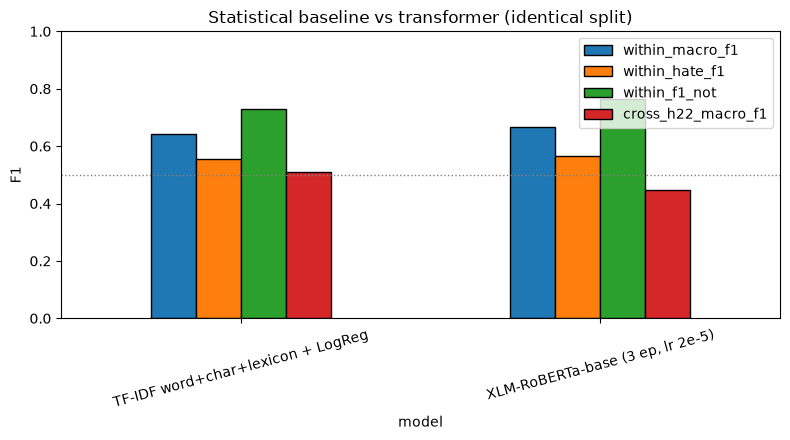

In [14]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
W = (PROJECT_ROOT / 'writing')
comparison = pd.DataFrame([
    {'model':'TF-IDF word+char+lexicon + LogReg','within_macro_f1':0.642,
     'within_hate_f1':0.555,'within_f1_not':0.729,'cross_h22_macro_f1':0.510},
    {'model':'XLM-RoBERTa-base (3 ep, lr 2e-5)','within_macro_f1':0.665,
     'within_hate_f1':0.565,'within_f1_not':0.764,'cross_h22_macro_f1':0.448},
])
comparison.to_csv(W/'model_comparison.csv', index=False)
ax = comparison.set_index('model').plot(kind='bar', figsize=(8,4.5), edgecolor='black', rot=15)
ax.set_ylabel('F1'); ax.set_ylim(0,1); ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_title('Statistical baseline vs transformer (identical split)')
plt.tight_layout(); plt.savefig(W/'figures/model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

### 12. Next model

To add MuRIL: set `MODEL_NAME = 'google/muril-base-cased'` in section 3 and re-run from
section 3 down. Results append to `transformer_results.csv` automatically, so nothing is
overwritten.

MuRIL is the one to expect most from, because it is pretrained on transliterated Roman-script
Indian-language text, which is exactly the input this project handles.

**Still outstanding after this notebook:**
- 5-fold CV on the transformer (this is a single split; the baseline headline is 5-fold)
- IndicBERT and the LoRA LLM
- The romanisation-variant attack from `variants.py`